# Smart Home Energy Forecasting

## Step 2: Load and preprocess the household electricity data

This section reads the original semicolon-separated dataset, parses its timestamps, cleans the `Global_active_power` target, and resamples it to 15-minute intervals. The original text file is read only; cleaned data is saved separately as `data/processed_energy.csv`.

The source dataset is checked in both the project root and the `data/` folder so this notebook works with the current project layout and the recommended layout.

In [11]:
from pathlib import Path

import pandas as pd

# The notebook is expected to be opened and run from the project folder.
PROJECT_ROOT = Path.cwd()
possible_dataset_paths = [
    PROJECT_ROOT / "data" / "household_power_consumption.txt",
    PROJECT_ROOT / "household_power_consumption.txt",
]

DATA_PATH = next(
    (path for path in possible_dataset_paths if path.is_file()),
    None,
)

if DATA_PATH is None:
    expected_paths = "\n".join(str(path) for path in possible_dataset_paths)
    raise FileNotFoundError(
        "Could not find household_power_consumption.txt. Checked:\n"
        f"{expected_paths}"
    )

print(f"Reading dataset from: {DATA_PATH}")

Reading dataset from: e:\EMEA\household_power_consumption.txt


## Load and inspect the original dataset

The file uses semicolons between columns. In this dataset, a question mark (`?`) marks a missing measurement, so Pandas reads it as a missing value.

In [7]:
raw_data = pd.read_csv(DATA_PATH, sep=";", na_values=["?"])

print(f"Rows: {raw_data.shape[0]:,}")
print(f"Columns: {raw_data.shape[1]}")
print("Column names:", raw_data.columns.tolist())

display(raw_data.head())
print("\nData types:")
display(raw_data.dtypes)
print("\nMissing values in each column:")
display(raw_data.isna().sum())

Rows: 2,075,259
Columns: 9
Column names: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



Data types:


Date                         str
Time                         str
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


Missing values in each column:


Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

## Parse timestamps and clean the target

The source stores the date and time in separate columns. We combine them into `Datetime` using the dataset's day/month/year date format. Invalid timestamps are marked as missing and removed; invalid power values become missing values.

In [8]:
required_columns = {"Date", "Time", "Global_active_power"}
missing_columns = required_columns.difference(raw_data.columns)
if missing_columns:
    raise ValueError(
        "Required columns are missing: " + ", ".join(sorted(missing_columns))
    )

energy_data = raw_data[["Date", "Time", "Global_active_power"]].copy()

# Combine the day/month/year date and time strings into one datetime column.
energy_data["Datetime"] = pd.to_datetime(
    energy_data["Date"].astype("string").str.strip()
    + " "
    + energy_data["Time"].astype("string").str.strip(),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce",
)

# Convert readings to numbers; anything invalid becomes NaN.
energy_data["Global_active_power"] = pd.to_numeric(
    energy_data["Global_active_power"], errors="coerce"
)

print(
    "Invalid or missing power readings after conversion:",
    int(energy_data["Global_active_power"].isna().sum()),
)
print("Invalid timestamps:", int(energy_data["Datetime"].isna().sum()))

# Keep the datetime and target, sort them in time order, and use time as the index.
energy_data = energy_data.dropna(subset=["Datetime"])
energy_data = energy_data[["Datetime", "Global_active_power"]]
energy_data = energy_data.sort_values("Datetime").set_index("Datetime")

display(energy_data.head())

Invalid or missing power readings after conversion: 25979
Invalid timestamps: 0


,Global_active_power
Datetime,
2006-12-16 17:24:00,4.216
2006-12-16 17:25:00,5.360
2006-12-16 17:26:00,5.374
2006-12-16 17:27:00,5.388
2006-12-16 17:28:00,3.666


## Fill internal gaps and resample to 15 minutes

Time interpolation fills missing readings only when valid readings exist on both sides. Remaining empty intervals (such as any edge gaps) are dropped. Each resampled value is the mean `Global_active_power` during that 15-minute interval.

In [9]:
energy_data["Global_active_power"] = energy_data["Global_active_power"].interpolate(
    method="time",
    limit_area="inside",
)

energy_15min = (
    energy_data["Global_active_power"]
    .resample("15min")
    .mean()
    .dropna()
    .rename("Global_active_power")
    .reset_index()
)
energy_15min = energy_15min[["Datetime", "Global_active_power"]]

print(f"Processed rows: {len(energy_15min):,}")
print("Processed columns:", energy_15min.columns.tolist())
display(energy_15min.head())
print("\nProcessed dataset information:")
energy_15min.info()
print("\nMissing values in processed data:")
display(energy_15min.isna().sum())

# Save to a new file; never write over household_power_consumption.txt.
OUTPUT_PATH = PROJECT_ROOT / "data" / "processed_energy.csv"
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
energy_15min.to_csv(OUTPUT_PATH, index=False)
print(f"\nSaved processed dataset to: {OUTPUT_PATH}")

Processed rows: 138,352
Processed columns: ['Datetime', 'Global_active_power']


,Datetime,Global_active_power
0,2006-12-16 17:15:00,4.587333
1,2006-12-16 17:30:00,4.140667
2,2006-12-16 17:45:00,4.159333
3,2006-12-16 18:00:00,4.121067
4,2006-12-16 18:15:00,3.768533



Processed dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 138352 entries, 0 to 138351
Data columns (total 2 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   Datetime             138352 non-null  datetime64[us]
 1   Global_active_power  138352 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 2.1 MB

Missing values in processed data:


Datetime               0
Global_active_power    0
dtype: int64


Saved processed dataset to: e:\EMEA\data\processed_energy.csv


## Step 3: Exploratory data analysis (EDA)

We will summarize the cleaned 15-minute `Global_active_power` readings and inspect their long-term pattern, a recent week of detail, and the value distribution. Power is shown in kilowatts (kW). These plots use the processed readings created above.

count    138352.000000
mean          1.090294
std           0.987060
min           0.078000
25%           0.322267
50%           0.664933
75%           1.561900
max           8.566133
Name: Global_active_power, dtype: float64

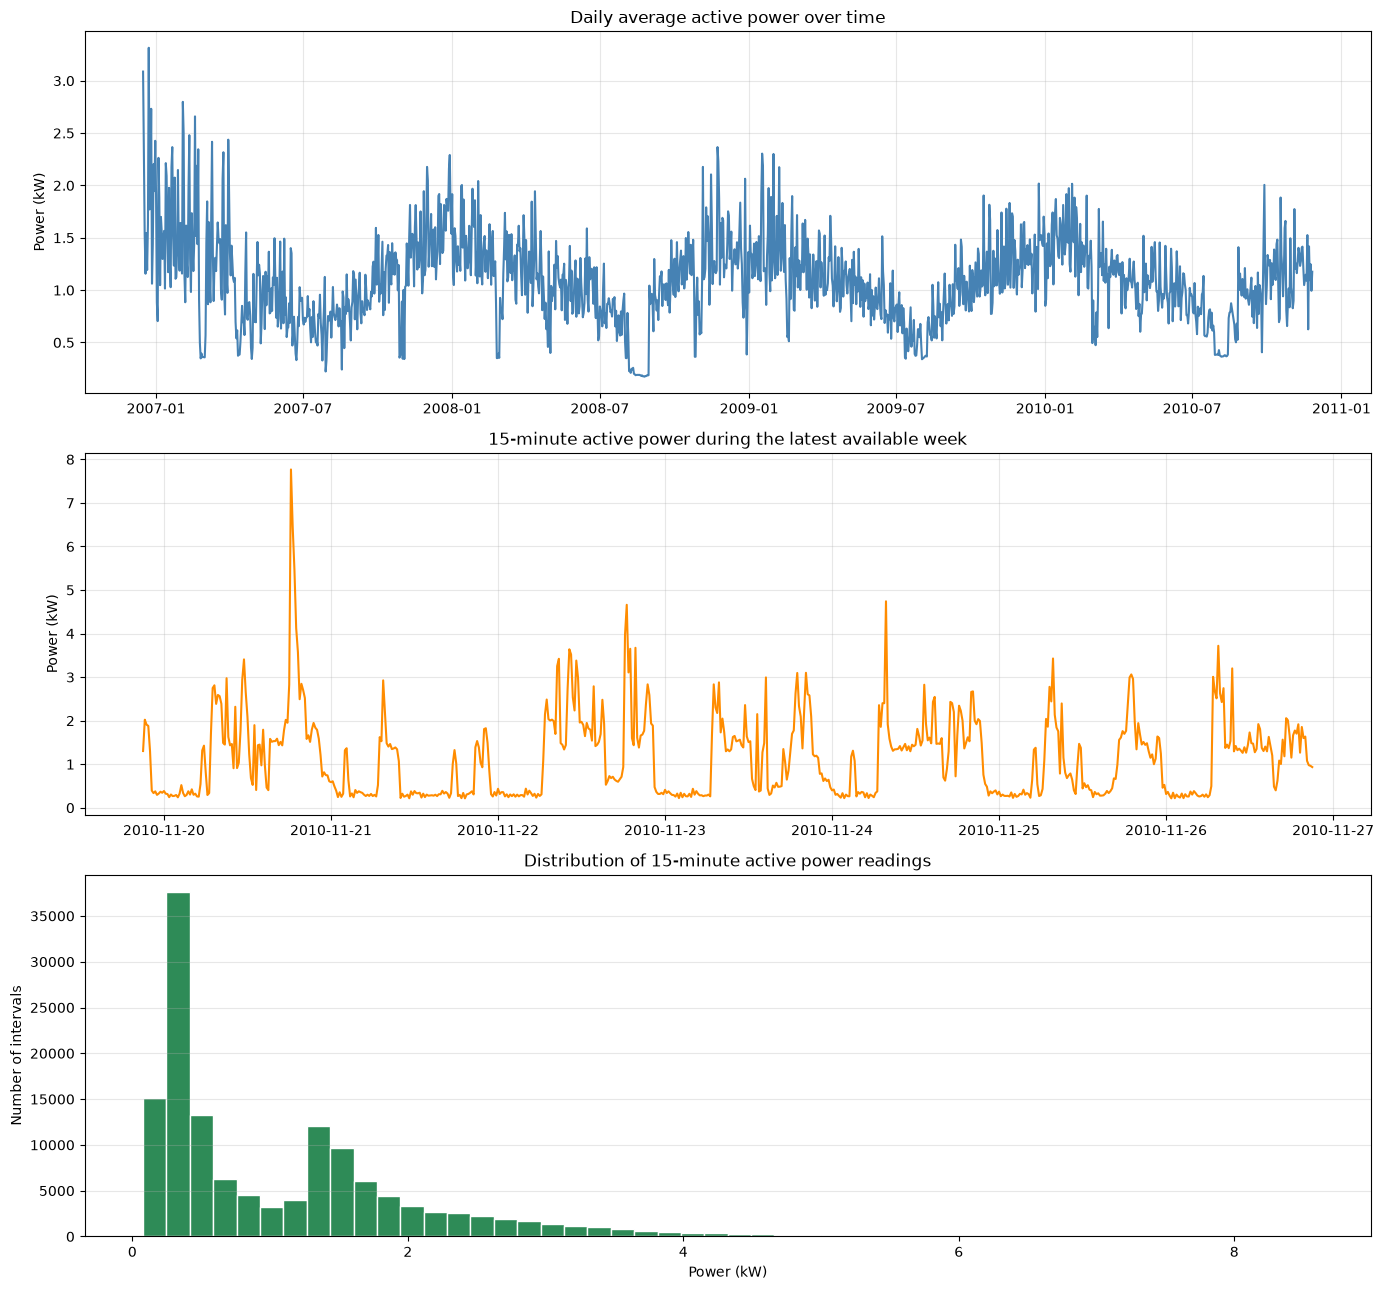

In [10]:
import matplotlib.pyplot as plt

# Show common summary statistics for the cleaned target values.
display(energy_15min["Global_active_power"].describe())

# Daily averages make the multi-year trend easier to view than every interval.
energy_by_time = energy_15min.set_index("Datetime")["Global_active_power"]
daily_average = energy_by_time.resample("D").mean().dropna()

fig, axes = plt.subplots(3, 1, figsize=(14, 13))

axes[0].plot(daily_average.index, daily_average.values, color="steelblue")
axes[0].set_title("Daily average active power over time")
axes[0].set_ylabel("Power (kW)")
axes[0].grid(True, alpha=0.3)

# Zoom in on the latest week to see the 15-minute changes more clearly.
last_timestamp = energy_by_time.index.max()
one_week_ago = last_timestamp - pd.Timedelta(days=7)
recent_week = energy_by_time.loc[one_week_ago:last_timestamp]
axes[1].plot(recent_week.index, recent_week.values, color="darkorange")
axes[1].set_title("15-minute active power during the latest available week")
axes[1].set_ylabel("Power (kW)")
axes[1].grid(True, alpha=0.3)

# A histogram shows how frequently different power levels occur.
axes[2].hist(energy_by_time, bins=50, color="seagreen", edgecolor="white")
axes[2].set_title("Distribution of 15-minute active power readings")
axes[2].set_xlabel("Power (kW)")
axes[2].set_ylabel("Number of intervals")
axes[2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()